In [1]:
#Imports
import pandas as pd
import yfinance as yf
import numpy as np
yf.set_tz_cache_location("../../data/raw/yahoo/py-yfinance-cache")  # relative to notebooks/00_foundations/

[*********************100%***********************]  1 of 1 completed


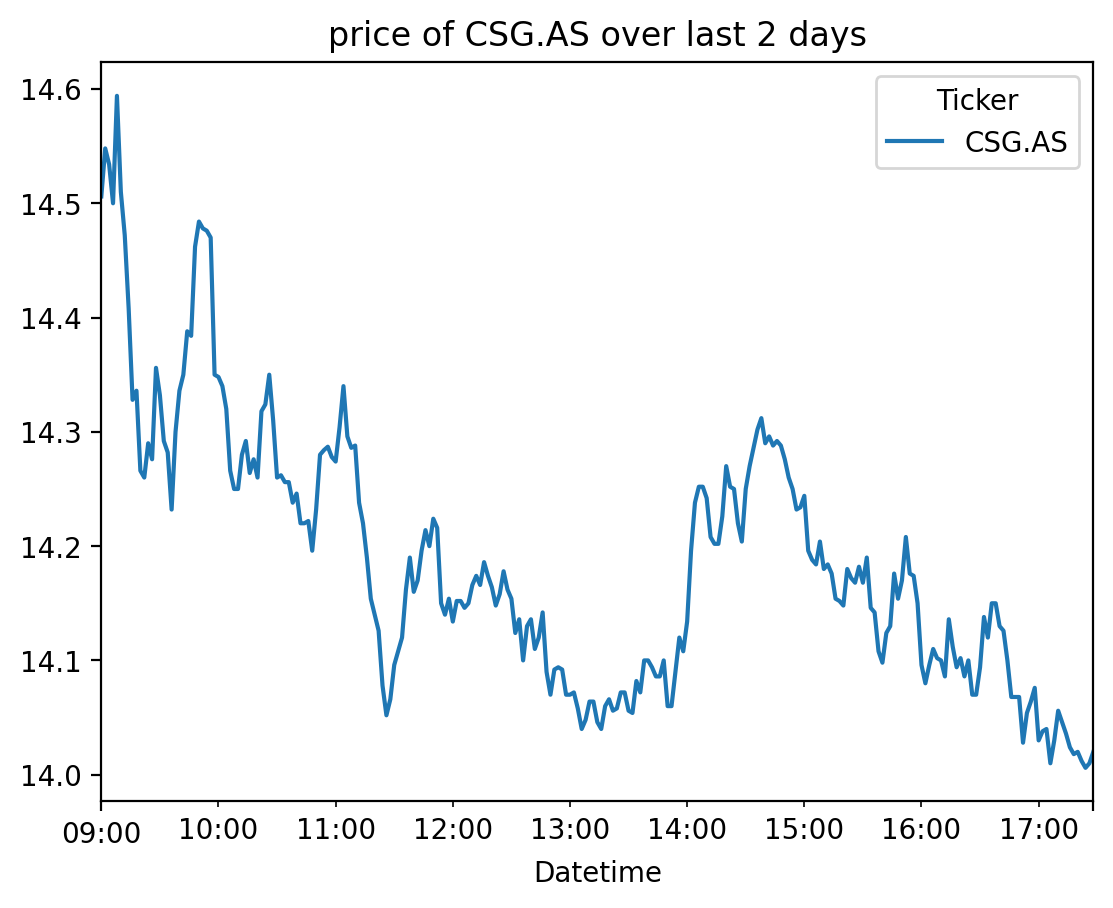

In [6]:
ticker = "CSG.AS"
df = yf.download(ticker, start= "2026-10-01", end= "2026-10-02", interval= "2m", prepost= True)

df.plot(y= "Close", kind= "line", title= f"price of {ticker} over last 2 days")
Series = df["Close"].squeeze("columns").to_numpy()

In [7]:
Series.shape

(255,)

In [8]:
m = 4 # Embedd dim
t = 4 # Delay

ε = 0.3 # Self explanatory

windows = np.lib.stride_tricks.sliding_window_view(Series, (m - 1) * t + 1)
vectors = windows[:, ::t] #VECTORS

In [9]:
Raw = np.zeros((len(vectors),len(vectors)),dtype= float)
Thresholded = np.zeros((len(vectors),len(vectors)),dtype= float)


for i in range(len(vectors)):
    for j in range(len(vectors)):
        Δ = (vectors[i] - vectors[j]) ** 2
        D = np.sqrt(np.sum(Δ))

        Raw[i,j] = D

        Thresholded[i,j] = D <= ε

In [11]:
import matplotlib.pyplot as plt

## Raw

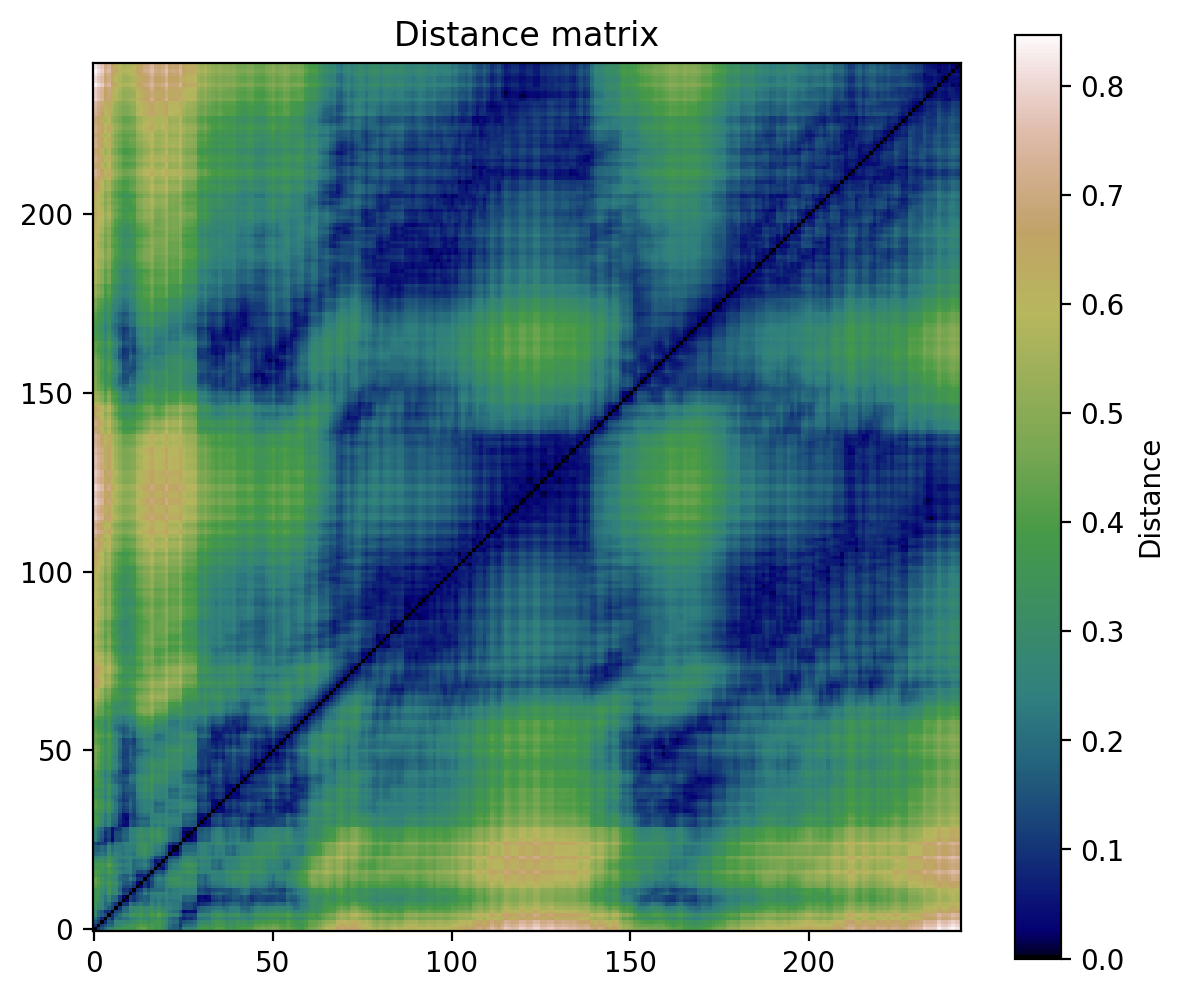

In [12]:
fig1, ax1 = plt.subplots(figsize=(7, 6))
im = ax1.imshow(Raw, cmap="gist_earth", origin="lower", interpolation="nearest")

ax1.set_title("Distance matrix")

fig1.colorbar(im, ax=ax1, label="Distance")
plt.show()

## Thresholded

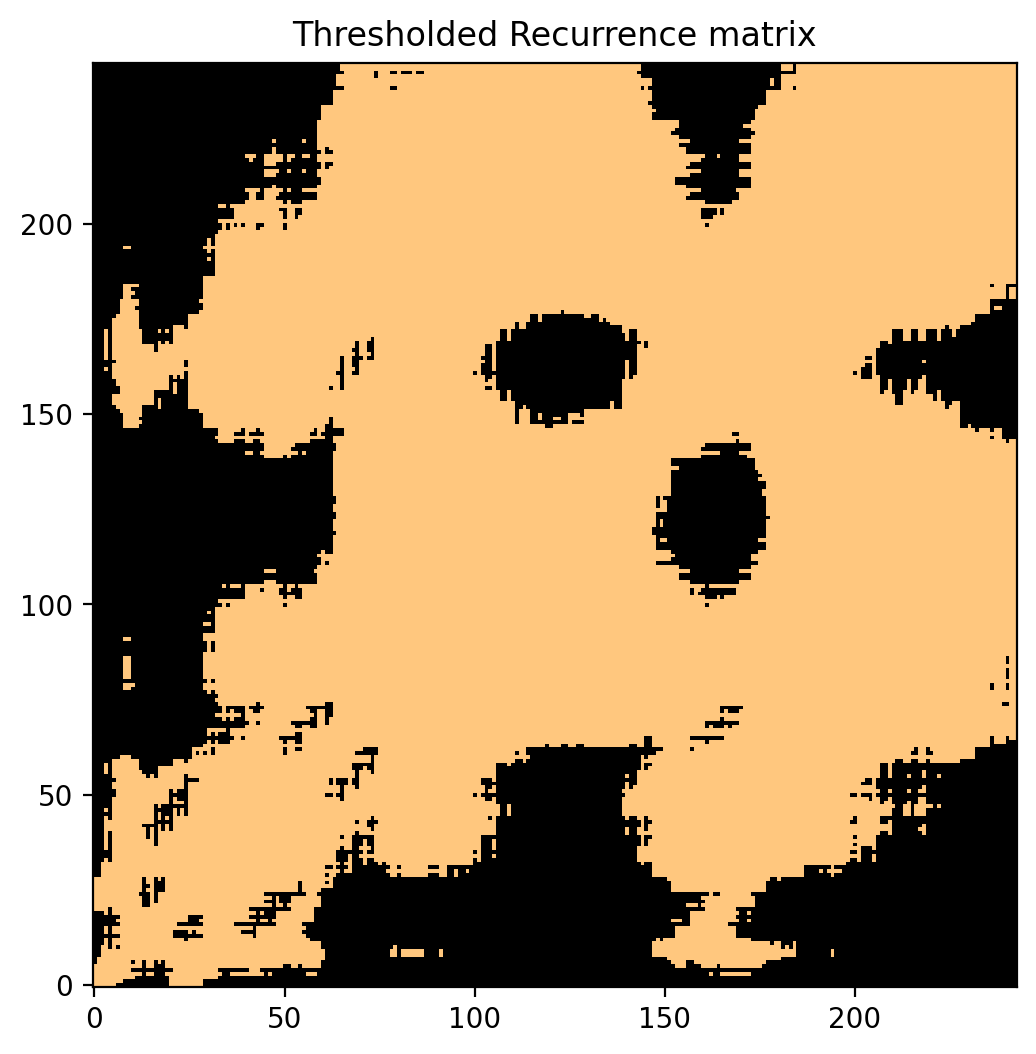

In [13]:
fig2, ax2 = plt.subplots(figsize=(7, 6))
im = ax2.imshow(Thresholded, cmap="copper", origin="lower", interpolation="nearest")

ax2.set_title("Thresholded Recurrence matrix")

#fig1.colorbar(im, ax=ax1, label="Distance")
plt.show()

## 3D: recurrence over continuous ε

A pair $(i, j)$ is recurrent for every $\varepsilon \ge D_{ij}$, so the continuous stack of thresholded plots is the solid **above** the surface $z = D_{ij}$.
The horizontal slice at height $\varepsilon$ is exactly the thresholded plot for that $\varepsilon$.
The z-axis stops at $\varepsilon_{max} = \max D_{ij}$, where RR reaches 100 %.

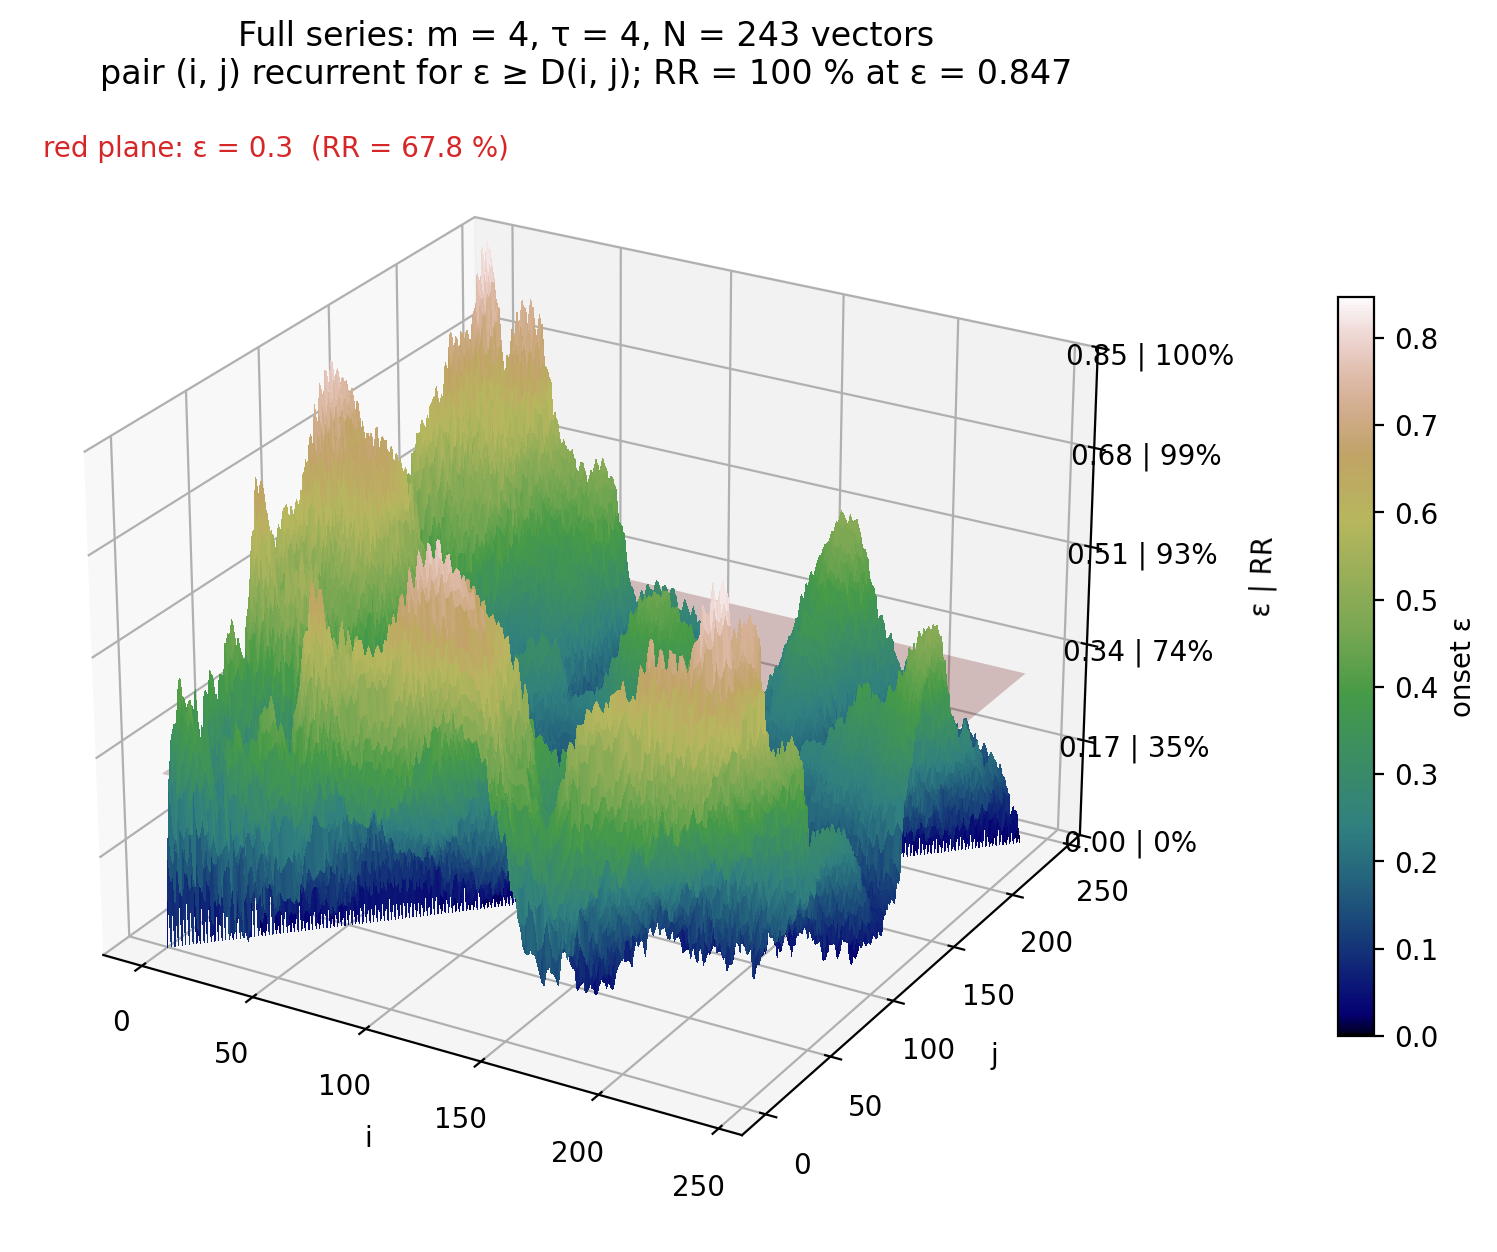

data   (embed, D, RR, grid):   0.0024 s
build  (surface, axes)     :   0.0861 s
render (plt.show)          :   5.2319 s
total                      :   5.3204 s


In [20]:
import time

def recurrence_3d(series, m, t, eps, label):
    """Embed `series` (dim m, delay t), plot the recurrence onset surface z = D(i, j)
    from ε = 0 up to ε_max (RR = 100 %), and print how long each stage took."""
    t0 = time.perf_counter()
    vecs = np.lib.stride_tricks.sliding_window_view(series, (m - 1) * t + 1)[:, ::t]
    D = np.sqrt(((vecs[:, None, :] - vecs[None, :, :]) ** 2).sum(axis=-1))  # same Euclidean distance as Raw
    N = D.shape[0]
    D_sorted = np.sort(D, axis=None)
    ε_max = D_sorted[-1]  # smallest ε with RR = 100 %
    if ε_max == 0:
        raise ValueError(f"{label}: all embedded vectors are identical (flat segment), RR is 100 % at ε = 0")

    def rr(e):
        """Recurrence rate (%) at threshold e, same `D <= ε` rule as Thresholded."""
        return 100 * np.searchsorted(D_sorted, e, side="right") / N**2

    I, J = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")
    t_data = time.perf_counter()

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection="3d")

    surf = ax.plot_surface(I, J, D, cmap="gist_earth", vmin=0, vmax=ε_max,
                           rstride=1, cstride=1, linewidth=0, antialiased=False)

    # Slice at ε: its footprint below the plane is the Thresholded plot
    if eps < ε_max:
        ax.plot_surface(I[[0, -1]][:, [0, -1]], J[[0, -1]][:, [0, -1]], np.full((2, 2), eps),
                        color="tab:red", alpha=0.25)
        ax.text2D(0.02, 0.95, f"red plane: ε = {eps}  (RR = {rr(eps):.1f} %)", color="tab:red", transform=ax.transAxes)
    else:
        ax.text2D(0.02, 0.95, f"ε = {eps} ≥ ε_max: RR = 100 %, plane above the plot", color="tab:red", transform=ax.transAxes)

    ax.set_zlim(0, ε_max)
    z_ticks = np.linspace(0, ε_max, 6)
    ax.set_zticks(z_ticks)
    ax.set_zticklabels([f"{z:.2f} | {rr(z):.0f}%" for z in z_ticks])

    ax.set_xlabel("i")
    ax.set_ylabel("j")
    ax.set_zlabel("ε | RR", labelpad=18)
    ax.set_title(f"{label}: m = {m}, τ = {t}, N = {N} vectors\n"
                 f"pair (i, j) recurrent for ε ≥ D(i, j); RR = 100 % at ε = {ε_max:.3f}")
    fig.colorbar(surf, ax=ax, shrink=0.6, pad=0.12, label="onset ε")
    ax.view_init(elev=25, azim=-60)
    t_build = time.perf_counter()
    plt.show()  # inline backend rasterises the N×N surface here; usually the dominant cost
    t_end = time.perf_counter()

    print(f"data   (embed, D, RR, grid): {t_data - t0:8.4f} s")
    print(f"build  (surface, axes)     : {t_build - t_data:8.4f} s")
    print(f"render (plt.show)          : {t_end - t_build:8.4f} s")
    print(f"total                      : {t_end - t0:8.4f} s")
    return D

D_full = recurrence_3d(Series, m, t, ε, "Full series")

## 3D on a 20-point chunk

Same plot for a 20-sample slice of `Series`, twice:
1. the notebook's embedding (`m`, `t` above): only $20 - (m-1)\tau$ vectors survive;
2. the $(m, \tau)$ with $m \ge 2$ that keeps the most vectors, i.e. the most original points as rows/columns of the plot. $N = n - (m-1)\tau$ is maximised by the smallest $(m-1)\tau$, so the search lands on $m = 2,\ \tau = 1$ ($N = 19$).

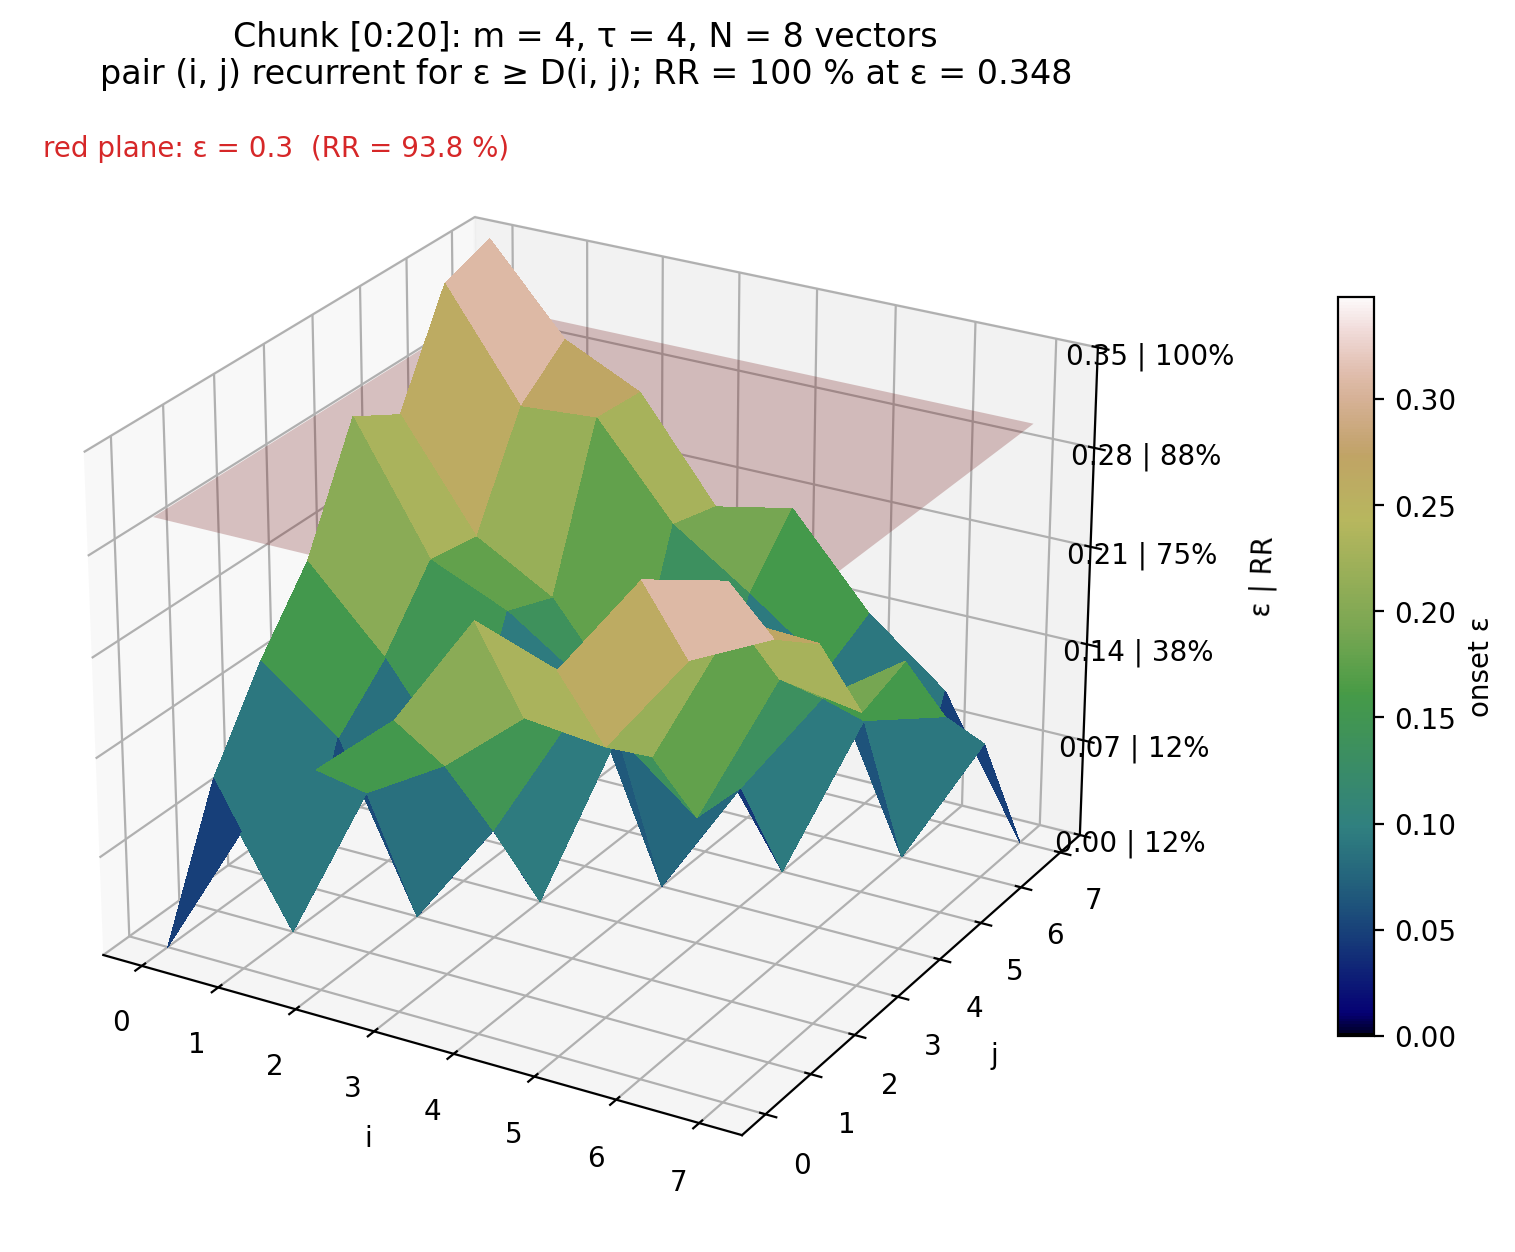

data   (embed, D, RR, grid):   0.0002 s
build  (surface, axes)     :   0.0213 s
render (plt.show)          :   0.1832 s
total                      :   0.2048 s


In [23]:
chunk_len = 20
chunk_start = 0  # shift to move the window along Series
chunk = Series[chunk_start:chunk_start + chunk_len]

D_chunk = recurrence_3d(chunk, m, t, ε, f"Chunk [{chunk_start}:{chunk_start + chunk_len}]")

best embedding: m = 2, τ = 1 → 19 of 20 points as vectors


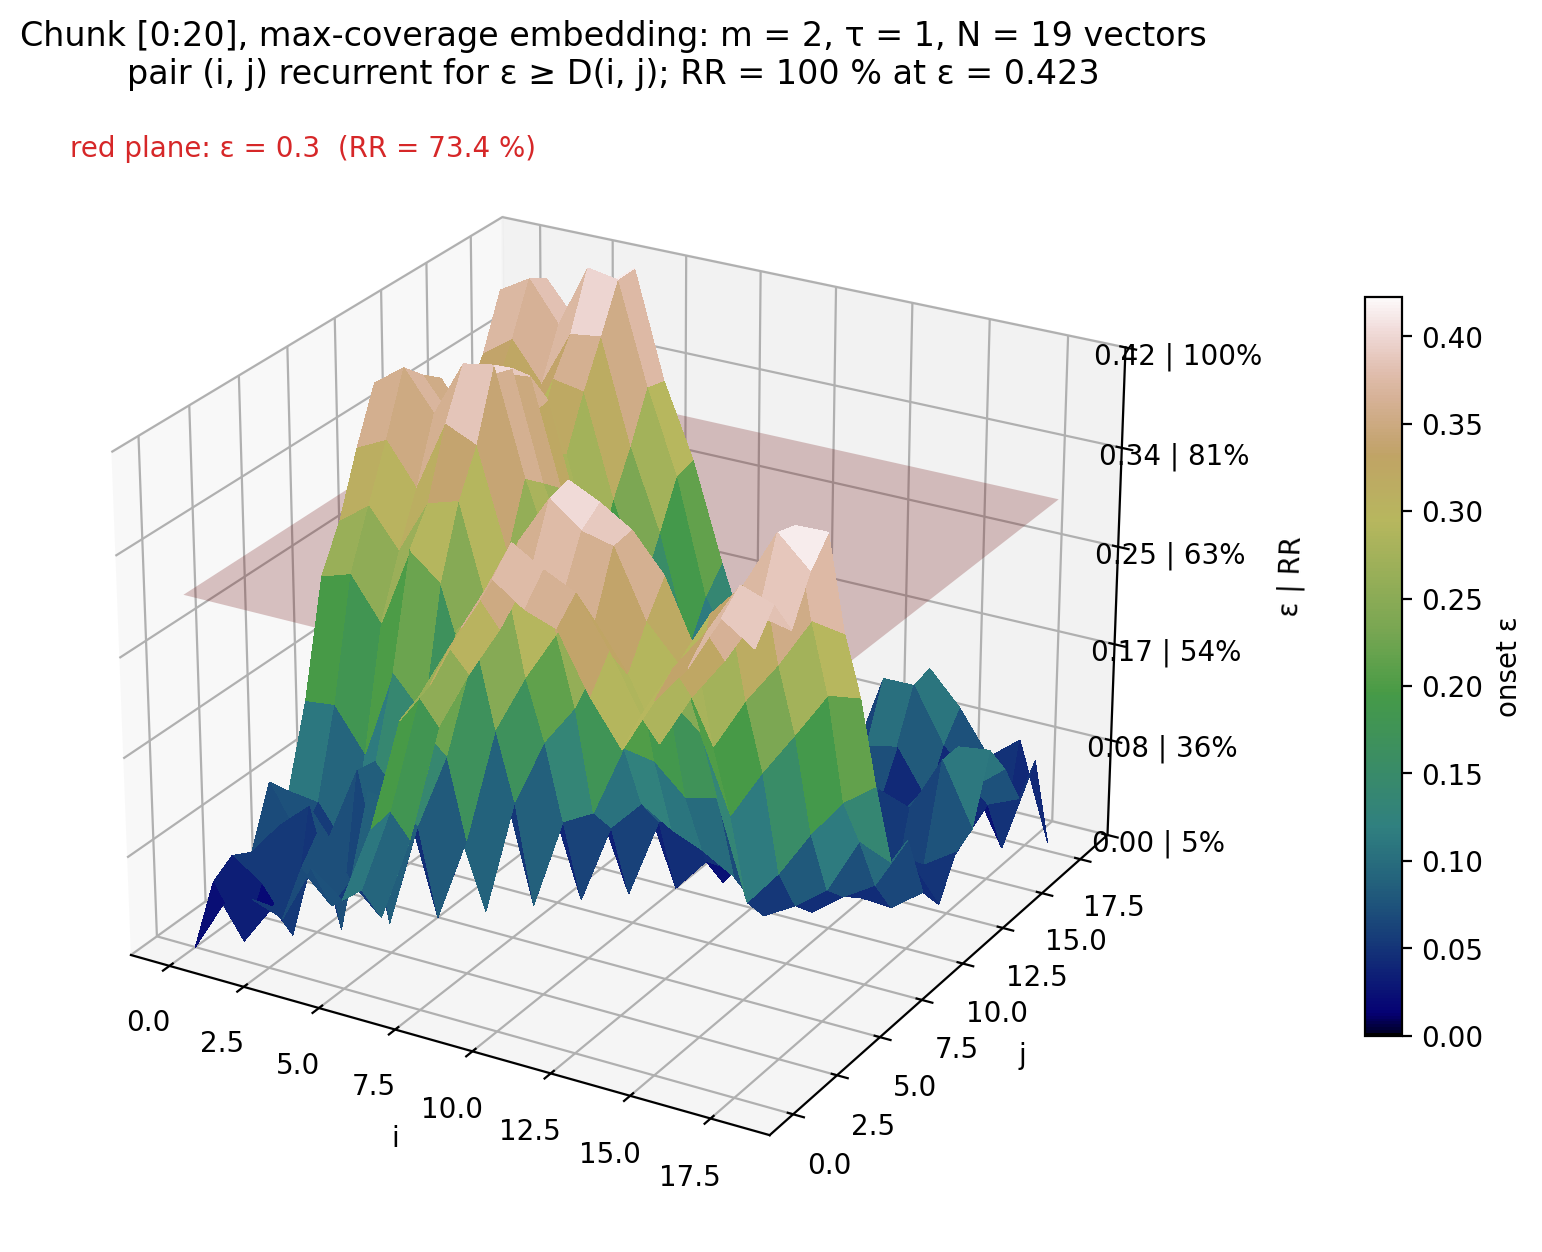

data   (embed, D, RR, grid):   0.0003 s
build  (surface, axes)     :   0.0231 s
render (plt.show)          :   0.3065 s
total                      :   0.3299 s


In [22]:
# m ≥ 2 (m = 1 is no embedding), at least 2 vectors; most vectors wins, larger m breaks ties
candidates = [(mm, tt) for mm in range(2, chunk_len) for tt in range(1, chunk_len)
              if chunk_len - (mm - 1) * tt >= 2]
m_best, t_best = max(candidates, key=lambda c: (chunk_len - (c[0] - 1) * c[1], c[0]))
print(f"best embedding: m = {m_best}, τ = {t_best} → {chunk_len - (m_best - 1) * t_best} of {chunk_len} points as vectors")

D_chunk_best = recurrence_3d(chunk, m_best, t_best, ε, f"Chunk [{chunk_start}:{chunk_start + chunk_len}], max-coverage embedding")

Rotatable version over time: `python recplay_3d_viewer.py` from this folder opens a window with one surface per sliding window of the series and a slider to step through them (`--help` for options).